# IADS5 · TP integrador — Ortelana Textil
### Actividad 04 · Reformulación del problema

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 04 · Reformulación del problema

**Qué se espera:** Como Ortelana tiene un target principal multiclase, proponé y justificá una reformulación binaria; para cumplir la rama de regresión del enunciado, definí además un target numérico genuino y entrená el modelo correspondiente. Compará con las baselines correctas.

**Evidencia a entregar:** Reformulación, modelos y métricas de las nuevas tareas.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

# Regresión de Metros2: mismas filas de train y test
features_reg = ["Sucursal_ID", "Tela_ID", "Año", "Metros1"]
Xr_train, Xr_test = train[features_reg], test[features_reg]
yr_train, yr_test = train["Metros2"], test["Metros2"]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
# 4.1 Reformulación binaria: alta frecuencia (B bimestral, M mensual: 6-12 períodos) = 1
#                           baja frecuencia (S semestral, C ciclo estacional: 2 períodos) = 0
yb_train = y_train.isin(["B", "M"]).astype(int)
yb_test = y_test.isin(["B", "M"]).astype(int)

print("Proporción de positivos -> train:", round(yb_train.mean(), 4), "| test:", round(yb_test.mean(), 4))
pd.crosstab(df["Format_Reporte"], df["Format_Reporte"].isin(["B", "M"]).astype(int).rename("y_binaria"))

Proporción de positivos -> train: 0.4559 | test: 0.4551


y_binaria,0,1
Format_Reporte,,
B,0,732
C,860,0
M,0,765
S,928,0


,Accuracy,Precision,Recall,F1,F1 macro
Baseline binaria,0.5449,0.0000,0.000,0.0000,0.3527
Logística binaria,0.8432,0.7899,0.893,0.8383,0.8431


Año       -0.1815
Metros1   -4.1855
Metros2   -0.4569
Name: coeficiente (log-odds de B/M), dtype: float64

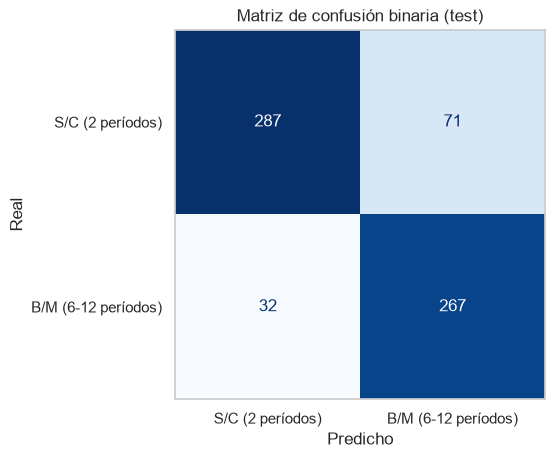

In [3]:
# 4.2 Baseline binaria y regresión logística binaria (mismas variables que en la actividad 03)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

num_cols = ["Año", "Metros1", "Metros2"]

pred_base_bin = DummyClassifier(strategy="most_frequent").fit(X_train, yb_train).predict(X_test)

logit_bin = Pipeline([("escalar", StandardScaler()),
                      ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
logit_bin.fit(X_train[num_cols], yb_train)
pred_logit_bin = logit_bin.predict(X_test[num_cols])

def metricas_bin(y_real, y_pred):
    return {"Accuracy": accuracy_score(y_real, y_pred),
            "Precision": precision_score(y_real, y_pred, zero_division=0),
            "Recall": recall_score(y_real, y_pred),
            "F1": f1_score(y_real, y_pred),
            "F1 macro": f1_score(y_real, y_pred, average="macro")}

display(pd.DataFrame([metricas_bin(yb_test, pred_base_bin), metricas_bin(yb_test, pred_logit_bin)],
                     index=["Baseline binaria", "Logística binaria"]).round(4))
display(pd.Series(logit_bin.named_steps["modelo"].coef_[0], index=num_cols,
                  name="coeficiente (log-odds de B/M)").round(4))

ConfusionMatrixDisplay.from_predictions(yb_test, pred_logit_bin, cmap="Blues", colorbar=False,
                                        display_labels=["S/C (2 períodos)", "B/M (6-12 períodos)"])
plt.title("Matriz de confusión binaria (test)")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.grid(False)
plt.show()

,MAE,MSE,RMSE,R2
Baseline (media),695.9745,853337.7914,923.7628,-0.0036
"Lineal (Año, Metros1)",231.9628,152355.5113,390.3274,0.8208
Lineal completa,219.4757,110588.3177,332.5482,0.8699


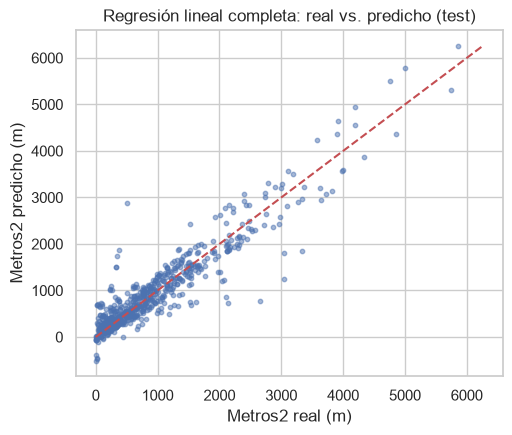

In [4]:
# 4.3 Rama de regresión: Metros2 con todas las features legítimas
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metricas_reg(y_real, y_pred):
    """MAE, MSE, RMSE y R² en metros."""
    mse = mean_squared_error(y_real, y_pred)
    return {"MAE": mean_absolute_error(y_real, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_real, y_pred)}

# Modelo lineal: k-1 dummies por variable categórica (drop="first"); la categoría omitida es la referencia
preprocesador = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["Sucursal_ID", "Tela_ID"]),
    ("num", "passthrough", ["Año", "Metros1"]),
])
lineal_completa = Pipeline([("prep", preprocesador), ("modelo", LinearRegression())])
lineal_completa.fit(Xr_train, yr_train)
pred_completa = lineal_completa.predict(Xr_test)

# Referencias: baseline (actividad 02) y regresión lineal solo numérica (actividad 03)
pred_media = DummyRegressor(strategy="mean").fit(Xr_train, yr_train).predict(Xr_test)
pred_numerica = LinearRegression().fit(Xr_train[["Año", "Metros1"]], yr_train).predict(Xr_test[["Año", "Metros1"]])

display(pd.DataFrame([metricas_reg(yr_test, pred_media),
                      metricas_reg(yr_test, pred_numerica),
                      metricas_reg(yr_test, pred_completa)],
                     index=["Baseline (media)", "Lineal (Año, Metros1)", "Lineal completa"]).round(4))

plt.figure(figsize=(5.5, 4.5))
plt.scatter(yr_test, pred_completa, s=10, alpha=0.5)
limite = max(yr_test.max(), pred_completa.max())
plt.plot([0, limite], [0, limite], "r--")
plt.title("Regresión lineal completa: real vs. predicho (test)")
plt.xlabel("Metros2 real (m)")
plt.ylabel("Metros2 predicho (m)")
plt.show()

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Reformulación binaria:** "¿el registro se reporta con **alta frecuencia** (mensual o bimestral, 6–12 períodos) o con **baja frecuencia** (semestral o ciclo estacional, 2 períodos)?".
  - Elegimos este corte porque agrupa los formatos según la granularidad temporal que describe la documentación del dataset, y los datos lo confirman (cantidad de períodos de cada formato).
  - Además deja dos grupos balanceados (45,6% de positivos).
- **Comparación:** la baseline binaria correcta (clase más frecuente, que es "C/S") contra una logística con las mismas variables numéricas de la Actividad 03.
- **Rama de regresión:** formalizamos `Metros2` como target genuino (metros, continuo, sin faltantes). Entrenamos una `LinearRegression` con todas las features legítimas: los identificadores codificados con k−1 dummies (una categoría de referencia, como indica la teoría para modelos lineales) más `Año` y `Metros1`, y la comparamos con la baseline de la media y con la regresión solo numérica.

**Interpretación de los resultados:**
- **Binaria:** pasa de accuracy 0,545 y F1 0 (la baseline nunca predice positivo) a **accuracy 0,843**, F1 = 0,838 y recall = 0,893 en la clase B/M.
  - El coeficiente dominante es `Metros1` (−4,19): cuanto mayor es el volumen del primer período, más probable es un formato de 2 períodos.
  - Los errores que quedan son registros de bajo volumen con formato C/S, o de alto volumen con formato B/M.
- **Regresión completa:** baja el RMSE de 390 m (solo numéricas) a **333 m** y sube el R² de 0,821 a **0,870**. La sucursal y la tela agregan información sobre el nivel de ventas.

**Pregunta de análisis:** ¿Qué información se pierde al simplificar la clasificación? ¿Cuándo convendría predecir una cantidad continua?
- **Qué se pierde:**
  - No distinguimos bimestral de mensual (6 contra 12 períodos) ni semestral de ciclo estacional, que tienen la misma cantidad de períodos pero cortan el año con criterios distintos.
  - La tarea binaria es más fácil (0,84 contra 0,73), pero responde una pregunta más pobre. No sirve si el uso requiere el formato exacto.
- **Cuándo predecir una cantidad continua:** cuando la decisión depende de una magnitud, como planificar stock, producción o compras de tela. Saber cuántos metros se van a vender es más accionable que una categoría. En ese caso conviene predecir `Metros2` directamente y medir el error en metros, en lugar de discretizar el volumen en rangos arbitrarios.

**Limitaciones o mejoras posibles:**
- La regresión supone que `Metros1` está disponible antes de que se conozca `Metros2`, algo plausible si los períodos son consecutivos.
- La relación sigue siendo heterocedástica.
- Según la descripción del dataset, `Metros2` cubre un período distinto según el formato: un mes en M, un bimestre en B, y un semestre o un ciclo en S y C. Como la regresión no usa `Format_Reporte`, mezcla esas escalas y la sucursal y la tela las capturan solo en parte. Agregar el formato como feature (se conoce al armar el reporte) o normalizar los metros por mes mejoraría el modelo.
- Para la binaria se podría ajustar el umbral de decisión según el costo de cada error.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
